In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer

In [ ]:
# Chargement et inspection
try:
    df_emp = pd.read_csv('employees.csv')
except FileNotFoundError:
    # Données de démonstration au cas où le fichier local n'existe pas
    data_demo = {
        'Employee_ID': [101, 102, 103, 104, 105],
        'First Name': ['Alice', 'Bob', np.nan, 'David', 'Eva'],
        'Gender': ['Female', 'Male', 'Male', np.nan, 'Female'],
        'Start Date': ['2020-01-15', '2019-03-12', '2021-06-01', '2018-11-20', np.nan],
        'Last Login Time': ['12:30 PM', '09:15 AM', np.nan, '02:45 PM', '08:00 AM'],
        'Salary': [70000, 85000, 62000, np.nan, 95000],
        'Bonus %': [11.5, 9.2, np.nan, 15.0, 12.3],
        'Senior Management': [True, False, True, np.nan, False],
        'Team': ['HR', 'IT', 'Finance', 'IT', np.nan]
    }
    df_emp = pd.DataFrame(data_demo)

print("=== 1. PREMIÈRES LIGNES (head) ===")
print(df_emp.head())

print("\n=== INFORMATIONS ET TYPES DE COLONNES ===")
print(df_emp.dtypes)

=== 1. PREMIÈRES LIGNES (head) ===
   Employee_ID First Name  Gender  Start Date Last Login Time   Salary  \
0          101      Alice  Female  2020-01-15        12:30 PM  70000.0   
1          102        Bob    Male  2019-03-12        09:15 AM  85000.0   
2          103        NaN    Male  2021-06-01             NaN  62000.0   
3          104      David     NaN  2018-11-20        02:45 PM      NaN   
4          105        Eva  Female         NaN        08:00 AM  95000.0   

   Bonus % Senior Management     Team  
0     11.5              True       HR  
1      9.2             False       IT  
2      NaN              True  Finance  
3     15.0               NaN       IT  
4     12.3             False      NaN  

=== INFORMATIONS ET TYPES DE COLONNES ===
Employee_ID            int64
First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary               float64
Bonus %              float64
Senior Management     object
Team 

In [ ]:
#  Comptage des valeurs manquantes brutes
print("=== 2. NOMBRE DE VALEURS MANQUANTES INITIALES ===")
print(df_emp.isna().sum())

=== 2. NOMBRE DE VALEURS MANQUANTES INITIALES ===
Employee_ID          0
First Name           1
Gender               1
Start Date           1
Last Login Time      1
Salary               1
Bonus %              1
Senior Management    1
Team                 1
dtype: int64


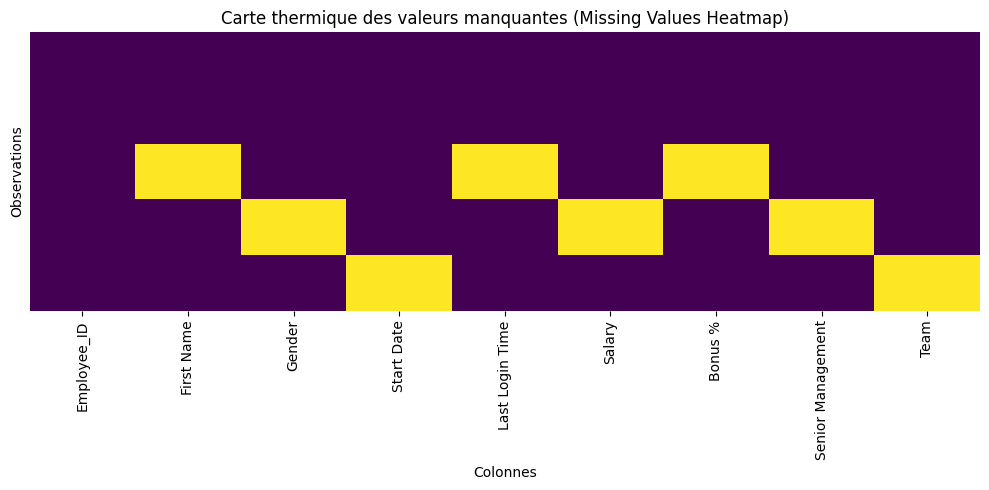

In [ ]:
# Visualisation Heatmap
plt.figure(figsize=(10, 5))
sns.heatmap(df_emp.isna(), cbar=False, cmap='viridis', yticklabels=False)

plt.title("Carte thermique des valeurs manquantes (Missing Values Heatmap)")
plt.xlabel("Colonnes")
plt.ylabel("Observations")
plt.tight_layout()

plt.savefig('missing_values_heatmap.png')
plt.show()

In [ ]:
#Copie du DataFrame et ajout de la ligne synthétique
df_copy = df_emp.copy()

synthetic_row = {
    'Employee_ID': 999,
    'First Name': '-',
    'Gender': 'na',
    'Start Date': 'N/A',
    'Last Login Time': '?',
    'Salary': np.nan,
    'Bonus %': np.nan,
    'Senior Management': 'None',
    'Team': 'na'
}

df_copy = pd.concat([df_copy, pd.DataFrame([synthetic_row])], ignore_index=True)

In [ ]:
#   Re-comptage après ajout de la ligne synthétique
print("=== 5. VALEURS MANQUANTES APRÈS AJOUT DE LA LIGNE SYNTHÉTIQUE ===")
print(df_copy.isna().sum())

=== 5. VALEURS MANQUANTES APRÈS AJOUT DE LA LIGNE SYNTHÉTIQUE ===
Employee_ID          0
First Name           1
Gender               1
Start Date           1
Last Login Time      1
Salary               2
Bonus %              2
Senior Management    1
Team                 1
dtype: int64


In [ ]:
#  Remplacement des marqueurs / placeholders par np.nan
placeholders = ['-', 'na', 'N/A', '?', 'None', 'n/a', 'NA']

df_cleaned = df_copy.replace(placeholders, np.nan)

print("=== 6. VALEURS MANQUANTES APRÈS NETTOYAGE DES PLACEHOLDERS ===")
print(df_cleaned.isna().sum())

=== 6. VALEURS MANQUANTES APRÈS NETTOYAGE DES PLACEHOLDERS ===
Employee_ID          0
First Name           2
Gender               2
Start Date           2
Last Login Time      2
Salary               2
Bonus %              2
Senior Management    2
Team                 2
dtype: int64


In [ ]:
#  Imputation par colonne avec SimpleImputer


num_cols = ['Salary', 'Bonus %']
cat_cols = ['Gender', 'Senior Management', 'Team']
id_cols = ['Employee_ID', 'First Name', 'Start Date', 'Last Login Time']


num_imputer = SimpleImputer(strategy='median')
df_cleaned[num_cols] = num_imputer.fit_transform(df_cleaned[num_cols])


cat_imputer = SimpleImputer(strategy='most_frequent')
df_cleaned[cat_cols] = cat_imputer.fit_transform(df_cleaned[cat_cols])

In [ ]:
#  Comparaison finale du nombre de valeurs manquantes
print("=== 8. COMPARAISON DU NOMBRE DE VALEURS MANQUANTES ===")
print("--- Avant imputation ---")
print(df_copy.isna().sum())

print("\n--- Après nettoyage et imputation (hors identifiants) ---")
print(df_cleaned.isna().sum())

=== 8. COMPARAISON DU NOMBRE DE VALEURS MANQUANTES ===
--- Avant imputation ---
Employee_ID          0
First Name           1
Gender               1
Start Date           1
Last Login Time      1
Salary               2
Bonus %              2
Senior Management    1
Team                 1
dtype: int64

--- Après nettoyage et imputation (hors identifiants) ---
Employee_ID          0
First Name           2
Gender               0
Start Date           2
Last Login Time      2
Salary               0
Bonus %              0
Senior Management    0
Team                 0
dtype: int64
